In [183]:
if (!requireNamespace("mixOmics", quietly = TRUE)) {
    options(BioC_mirror = "https://bioconductor.org")
    BiocManager::install(version = "3.18", force = TRUE)
    BiocManager::install("mixOmics")
}

library(mixOmics)
library(BiocParallel)
library(svglite)

In [184]:
DATA_DIR <- "/home/mariya/Data/pallas"
MIXOMICS_DIR <- file.path(DATA_DIR, "mixOmics/models_20260625_keepX100")
PREDICTIONS_OUTPUT_DIR <- "/home/mariya/Development/pallas/reports/output/predictions/bimodal"
REPORT_OUTPUT_DIR <- "/home/mariya/Development/pallas/reports/output/evaluation/bimodal"

DATA_DIR <- file.path(DATA_DIR, "mlomix_datasets")

TRAIN_DATA_DIR <- file.path(DATA_DIR, "train-bimodal-reduced")
TRAIN_LABELS_FILE <- file.path(TRAIN_DATA_DIR, "labels.csv")

TEST_DATA_DIR <- file.path(DATA_DIR, "test-bimodal-reduced")
METH_TEST_FILE <- file.path(TEST_DATA_DIR, "features.dnam.csv")
GEX_TEST_FILE <- file.path(TEST_DATA_DIR, "features.gex.csv")
LABELS_TEST_FILE <- file.path(TEST_DATA_DIR, "labels.csv")

GEX_MODEL_FILE <- file.path(MIXOMICS_DIR, "gex_model.rds")
DNAM_MODEL_FILE <- file.path(MIXOMICS_DIR, "dnam_model.rds")
DIABLO_MODEL_FILE <- file.path(MIXOMICS_DIR, "diablo_model.rds")

# Make output directory if it doesn't exist
if (!dir.exists(PREDICTIONS_OUTPUT_DIR)) {
    dir.create(PREDICTIONS_OUTPUT_DIR, recursive = TRUE)
}

In [185]:
BLUE="#667ec8"
RED="#d64a51"
YELLOW="#d6ce2f"
GREEN="#90c23a"
LIGHTBLUE="#60acda"
PURPLE="#9454b0"

In [186]:
# Reload in a fresh session with
gex_model    <- readRDS(GEX_MODEL_FILE)
dnam_model   <- readRDS(DNAM_MODEL_FILE)
diablo_model <- readRDS(DIABLO_MODEL_FILE)


In [187]:
source("helpers.R")
test_data <- data(GEX_TEST_FILE, METH_TEST_FILE, LABELS_TEST_FILE)

Samples: 368 
GEX features: 199 
DNAm features: 6582 
Subtypes: AML, APL-PML::RARA AML, CBFA2T3::GLIS2 AML, CBFB::MYH11 AML, CEBPAalt AML, DEK::NUP214 AML, ETV6-r AML, KAT6A-r AML, KMT2A-r AML, NPM1alt AML, NUP98-r AML, RUNX1::RUNX1T1 B-ALL, BCR::ABL1 B-ALL, BCR::ABL1-like B-ALL, DUX4-r B-ALL, ETV6::RUNX1 B-ALL, ETV6::RUNX1-like B-ALL, high hyperdiploid B-ALL, iAMP21 B-ALL, KMT2A-r B-ALL, MEF2D-r B-ALL, PAX5alt B-ALL, TCF3::PBX1 B-ALL, ZNF384-r Non-leukemic T-ALL 


In [188]:
# Also read in train labels to use in charts
train_labels <- read.csv(TRAIN_LABELS_FILE, row.names = 1)
train_labels

,class
,<chr>
ALL_1000,"B-ALL, DUX4-r"
ALL_1003,"B-ALL, PAX5alt"
ALL_1005,"B-ALL, MEF2D-r"
ALL_1019,"B-ALL, ZNF384-r"
ALL_1031,"B-ALL, BCR::ABL1-like"
ALL_1039,"B-ALL, BCR::ABL1"
ALL_1047,"B-ALL, ETV6::RUNX1-like"
ALL_1056,"B-ALL, MEF2D-r"
ALL_1060,"B-ALL, ETV6::RUNX1"


In [189]:
X_gex_test <- test_data$X_gex
X_dnam_test <- test_data$X_dnam
Y_test     <- test_data$Y
Y_train    <- train_labels$class

head(X_gex_test)
head(X_dnam_test)
head(Y_test)
head(Y_train)

,ENSG00000079102,ENSG00000175505,ENSG00000185917,ENSG00000145113,ENSG00000102098,ENSG00000248329,ENSG00000164853,ENSG00000173825,ENSG00000073792,ENSG00000067177,⋯,ENSG00000164741,ENSG00000167528,ENSG00000114757,ENSG00000189325,ENSG00000132780,ENSG00000106004,ENSG00000175591,ENSG00000188269,ENSG00000142599,ENSG00000106665
ALL_1023,-1.514703,2.2746706,3.623815,-1.3310038,5.460389,-1.514703,-1.514703,2.5321066,5.850828,0.13264308,⋯,1.5066989,2.247654,-1.4174740,0.4698004,7.270938,6.021581,1.773157,-1.5147034,4.712570,5.894605
ALL_1026,-1.514703,0.0750794,3.472827,-1.2813560,3.729588,-1.002332,-1.514703,0.9047167,5.534175,0.95190484,⋯,-1.2850114,3.642856,-1.5147034,-1.2623305,6.645966,-1.514703,-1.514703,-0.5004006,5.907985,6.750181
ALL_1058,-1.514703,1.0255064,2.879665,-1.1481926,3.994490,3.050333,-1.514703,2.5968255,2.775407,1.37925037,⋯,-1.0419840,3.305464,-1.5147034,-1.5147034,5.957099,4.674769,1.718673,-1.5147034,4.779633,6.577621
ALL_106,-1.514703,1.6373373,3.689083,-1.4738668,5.871467,-1.514703,-1.514703,1.2391541,3.502574,1.00788692,⋯,0.5552362,3.233930,-0.9005658,3.4759482,7.052744,-1.080801,3.249507,-1.1608261,5.927997,6.559402
ALL_1061,-1.514703,1.9745518,2.857876,-1.4619699,2.732917,-1.514703,-1.514703,1.2989722,4.926858,-0.06940321,⋯,-0.1440415,2.490534,-1.5147034,-1.5147034,5.994176,4.920549,2.000600,-1.5147034,5.182285,6.191974
ALL_1081,-1.514703,0.9128547,1.799598,-0.8800579,4.327297,-1.514703,-1.514703,0.8597102,4.540639,-0.70777063,⋯,-1.2409840,3.166868,-1.5147034,-1.3077165,6.071948,-1.514703,-1.514703,-1.5147034,5.018425,4.579600


,cg17259886,cg13293524,cg16288865,cg12923179,cg11622162,cg07232063,cg03763508,cg18638389,cg02707071,cg08166720,⋯,cg19557110,cg08911692,cg05807885,cg00527174,cg08473752,cg08870143,cg06814191,cg06710207,cg08523727,cg06671690
ALL_1023,0.9551,0.9766,0.9477,0.9347,0.0551,0.9443,0.9670,0.2137,0.9445,0.9532,⋯,0.9652,0.9570,0.3215,0.0912,0.9539,0.9653,0.9485,0.9255,0.9453,0.0269
ALL_1026,0.9517,0.9781,0.9422,0.9029,0.0417,0.6634,0.9543,0.9476,0.9522,0.9592,⋯,0.9650,0.7296,0.0639,0.4370,0.9487,0.7009,0.9342,0.9293,0.4868,0.0120
ALL_1058,0.9564,0.9760,0.2672,0.9301,0.0512,0.9095,0.9469,0.9279,0.9472,0.9472,⋯,0.9525,0.9479,0.0623,0.0584,0.9493,0.9251,0.9333,0.9185,0.2346,0.1216
ALL_106,0.9650,0.9852,0.9502,0.9416,0.0822,0.9296,0.9654,0.4650,0.9585,0.9647,⋯,0.9743,0.9657,0.1071,0.0425,0.9618,0.9395,0.9575,0.9485,0.9331,0.0119
ALL_1061,0.9562,0.9721,0.5987,0.9374,0.0406,0.5283,0.9511,0.9315,0.9537,0.9329,⋯,0.9425,0.9484,0.4919,0.1149,0.9440,0.9344,0.9303,0.8934,0.9354,0.0121
ALL_1081,0.9594,0.9771,0.9414,0.7457,0.0460,0.7262,0.9390,0.9323,0.9581,0.9476,⋯,0.9708,0.9578,0.7071,0.5017,0.9409,0.8831,0.9327,0.9152,0.9296,0.1425


[1] B-ALL, ETV6::RUNX1      B-ALL, PAX5alt          B-ALL, DUX4-r          
[4] B-ALL, ETV6::RUNX1-like B-ALL, PAX5alt          B-ALL, TCF3::PBX1      
25 Levels: AML, APL-PML::RARA AML, CBFA2T3::GLIS2 ... T-ALL

[1] "B-ALL, DUX4-r"         "B-ALL, PAX5alt"        "B-ALL, MEF2D-r"       
[4] "B-ALL, ZNF384-r"       "B-ALL, BCR::ABL1-like" "B-ALL, BCR::ABL1"

In [190]:
# X_gex_test  <- X_gex_test[,  colnames(gex_model$X)]
# X_dnam_test <- X_dnam_test[, colnames(dnam_model$X)]

# Verify
cat("GEX names match: ",  all(colnames(X_gex_test)  == colnames(gex_model$X)),  "\n")
cat("DNAm names match:",  all(colnames(X_dnam_test) == colnames(dnam_model$X)), "\n")

# Show number of features in test set vs model
cat("GEX features in test set: ", ncol(X_gex_test), " vs model: ", ncol(gex_model$X), "\n")
cat("DNAm features in test set: ", ncol(X_dnam_test), " vs model: ", ncol(dnam_model$X), "\n")

GEX names match:  TRUE 
DNAm names match: TRUE 
GEX features in test set:  199  vs model:  199 


DNAm features in test set:  6582  vs model:  6582 


In [191]:

gex_pred    <- predict(gex_model,    X_gex_test,  dist = "max.dist")
dnam_pred   <- predict(dnam_model,   X_dnam_test, dist = "max.dist")
diablo_pred <- predict(diablo_model, newdata = list(gex = X_gex_test,
                                                     dnam = X_dnam_test),
                                                     dist = "max.dist")

In [ ]:
# Extract predicted classes at final component
ncomp_gex_final    <- gex_model$ncomp
ncomp_dnam_final   <- dnam_model$ncomp
ncomp_diablo_final <- diablo_model$ncomp

gex_class    <- gex_pred$class$max.dist[,    ncomp_gex_final]
dnam_class   <- dnam_pred$class$max.dist[,   ncomp_dnam_final]
diablo_class <- diablo_pred$WeightedVote$max.dist[, ncol(diablo_pred$WeightedVote$max.dist)]

In [ ]:
# Make predictiosn dir if not exist
if (!dir.exists(PREDICTIONS_OUTPUT_DIR)) {
    dir.create(PREDICTIONS_OUTPUT_DIR, recursive = TRUE)
}

# After true_label, create three cols: gex_pred, dnam_pred, diablo_pred
# that contain the prediction from the MAX_COMP component for each model
# Keep the rest of the columns as well
predictions_df <- data.frame(
    "Sample" = rownames(X_gex_test),
    "True subtype" = Y_test,
    "GEX sPLS-DA prediction" = gex_class,
    "DNAm sPLS-DA prediction" = dnam_class,
    "DIABLO sPLS-DA prediction" = diablo_class,
    "GEX" = gex_pred$class,
    "DNAm" = dnam_pred$class,
    "DIABLO" = diablo_pred$class,
    check.names = FALSE
)

# Sort by "True subtype", then "Sample"
predictions_df <- predictions_df[order(predictions_df$`True subtype`, predictions_df$Sample), ]

write.csv(predictions_df, file.path(PREDICTIONS_OUTPUT_DIR, "test_predictions.csv"), row.names = FALSE)

In [ ]:
# Build results data frame
results_df <- data.frame(
  sample_id   = rownames(X_gex_test),
  true_label  = as.character(Y_test),
  gex_pred    = as.character(gex_class),
  dnam_pred   = as.character(dnam_class),
  diablo_pred = as.character(diablo_class),
  row.names   = NULL
)

head(results_df)

,sample_id,true_label,gex_pred,dnam_pred,diablo_pred
,<chr>,<chr>,<chr>,<chr>,<chr>
1,ALL_1023,"B-ALL, ETV6::RUNX1","B-ALL, ETV6::RUNX1","B-ALL, ETV6::RUNX1","B-ALL, ETV6::RUNX1"
2,ALL_1026,"B-ALL, PAX5alt","AML, NPM1alt","B-ALL, PAX5alt","B-ALL, PAX5alt"
3,ALL_1058,"B-ALL, DUX4-r","B-ALL, ZNF384-r","B-ALL, DUX4-r","B-ALL, DUX4-r"
4,ALL_106,"B-ALL, ETV6::RUNX1-like","B-ALL, ETV6::RUNX1-like","B-ALL, ETV6::RUNX1-like","B-ALL, ETV6::RUNX1-like"
5,ALL_1061,"B-ALL, PAX5alt","B-ALL, PAX5alt","B-ALL, PAX5alt","B-ALL, PAX5alt"
6,ALL_1081,"B-ALL, TCF3::PBX1","B-ALL, TCF3::PBX1","B-ALL, TCF3::PBX1","B-ALL, TCF3::PBX1"


In [ ]:

library(ggplot2)
library(dplyr)
library(tidyr)
library(ggrepel)

# Per-class F1
per_class_f1 <- function(true, pred, classes) {
  do.call(rbind, lapply(classes, function(c) {
    tp <- sum(pred == c & true == c)
    fp <- sum(pred == c & true != c)
    fn <- sum(pred != c & true == c)
    precision <- ifelse((tp + fp) == 0, 0, tp / (tp + fp))
    recall    <- ifelse((tp + fn) == 0, 0, tp / (tp + fn))
    f1        <- ifelse((precision + recall) == 0, 0,
                        2 * precision * recall / (precision + recall))
    data.frame(Class = c, Precision = round(precision, 3),
               Recall = round(recall, 3), F1 = round(f1, 3))
  }))
}

classes <- levels(Y_test)

f1_gex    <- per_class_f1(Y_test, gex_class,    classes); f1_gex$Model    <- "GEX"
f1_dnam   <- per_class_f1(Y_test, dnam_class,   classes); f1_dnam$Model   <- "DNAm"
f1_diablo <- per_class_f1(Y_test, diablo_class, classes); f1_diablo$Model <- "DIABLO"

f1_all  <- rbind(f1_gex, f1_dnam, f1_diablo)
f1_wide <- f1_all |> select(Class, Model, F1) |>
  pivot_wider(names_from = Model, values_from = F1)

# Add class sizes
class_n_train       <- as.data.frame(table(Y_train))
colnames(class_n_train) <- c("Class", "n_train")
f1_wide        <- left_join(f1_wide, class_n_train, by = "Class")

class_n_test        <- as.data.frame(table(Y_test))
colnames(class_n_test) <- c("Class", "n_test")
f1_wide        <- left_join(f1_wide, class_n_test, by = "Class")
f1_wide

Class,GEX,DNAm,DIABLO,n_train,n_test
<chr>,<dbl>,<dbl>,<dbl>,<int>,<int>
"AML, APL-PML::RARA",0.857,0.857,0.857,10,4
"AML, CBFA2T3::GLIS2",1.000,1.000,0.889,9,4
"AML, CBFB::MYH11",0.980,1.000,1.000,58,25
"AML, CEBPAalt",0.952,0.976,0.976,50,21
"AML, DEK::NUP214",0.933,1.000,1.000,19,8
"AML, ETV6-r",0.800,1.000,0.800,6,3
"AML, KAT6A-r",0.667,0.667,0.000,5,2
"AML, KMT2A-r",0.940,0.944,0.923,206,89
"AML, NPM1alt",0.847,0.952,0.971,115,50


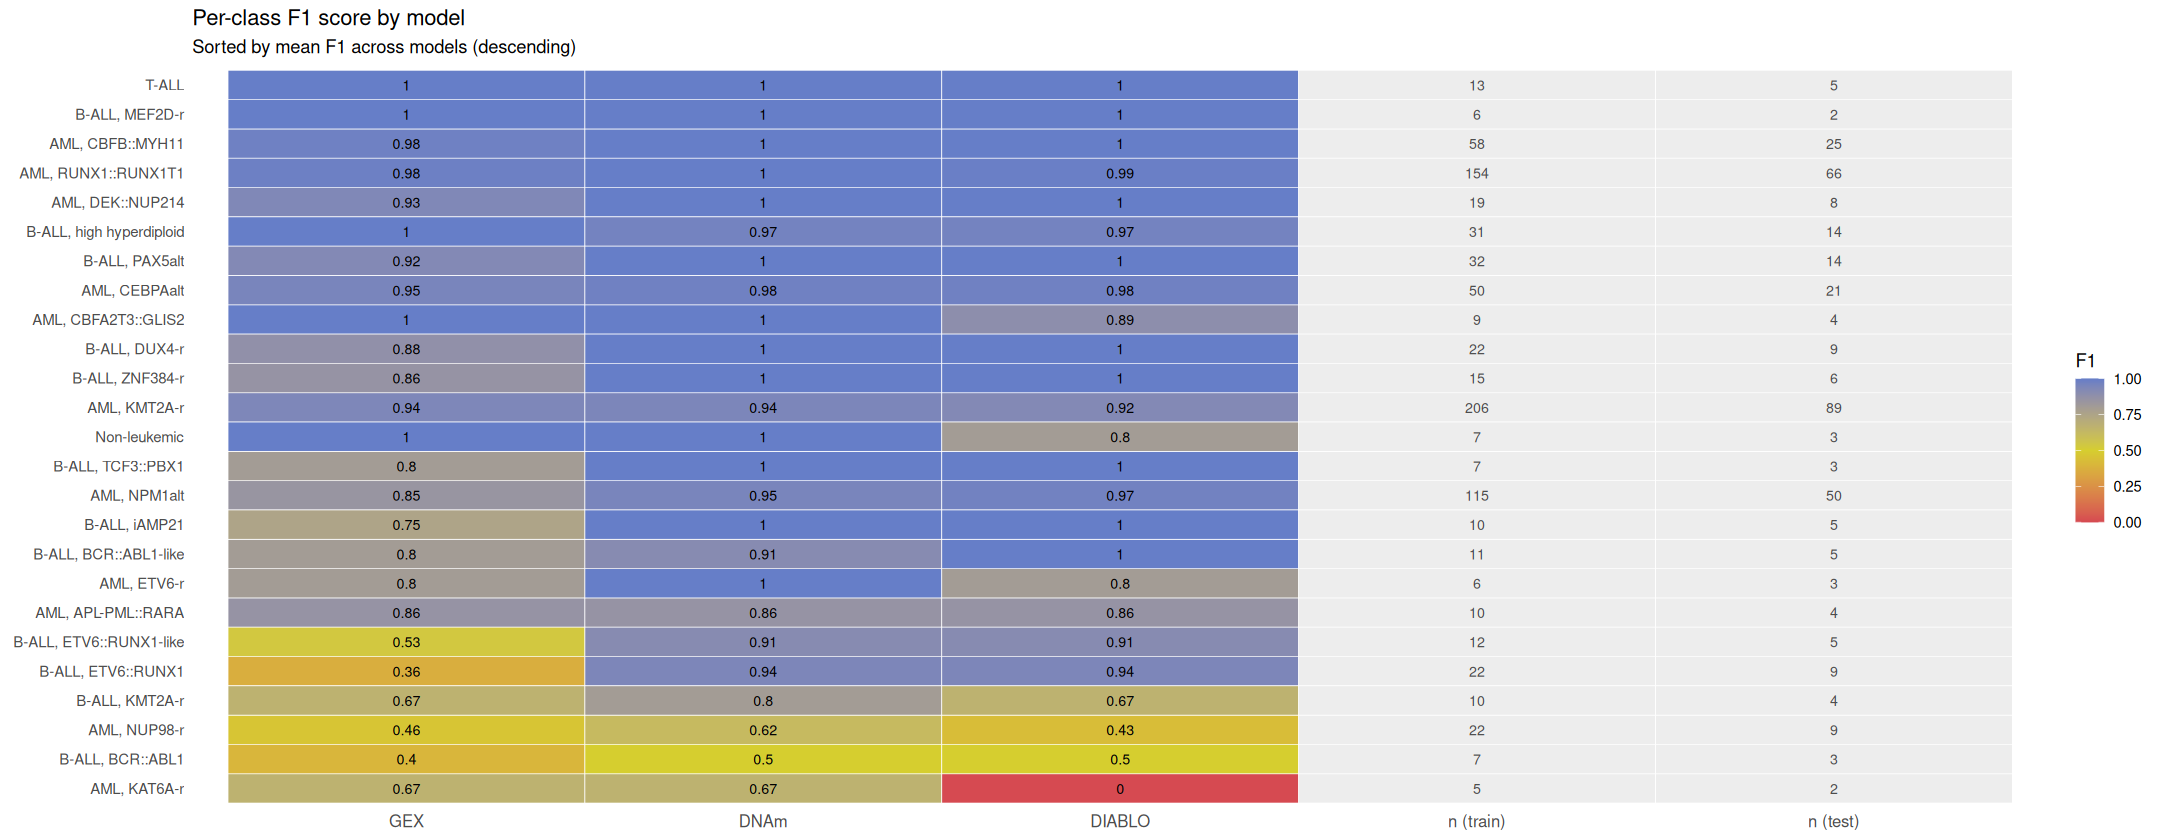

In [192]:
# Add average F1 column for sorting
f1_wide <- f1_wide %>%
  mutate(avg_F1 = (GEX + DNAm + DIABLO) / 3)

# Pivot to long including n_train and n_test as separate tile columns
f1_long <- f1_wide %>%
  pivot_longer(cols = c("GEX", "DNAm", "DIABLO"),
               names_to = "Model", values_to = "F1")

# Create n_train and n_test rows as separate "columns"
n_df <- f1_wide %>%
  select(Class, n_train, n_test, avg_F1) %>%
  pivot_longer(cols = c("n_train", "n_test"),
               names_to = "Model", values_to = "n_val") %>%
  mutate(F1 = NA)

# Combine
f1_plot_df <- bind_rows(
  f1_long %>% mutate(n_val = NA),
  n_df
) %>%
  mutate(Model = factor(Model,
                        levels = c("GEX", "DNAm", "DIABLO",
                                   "n_train", "n_test")))

ggplot(f1_plot_df,
       aes(x = Model,
           y = reorder(Class, avg_F1),
           fill = F1)) +
  geom_tile(colour = "white") +
  # F1 values
  geom_text(data = filter(f1_plot_df, Model %in% c("GEX","DNAm","DIABLO")),
            aes(label = round(F1, 2)), size = 3) +
  # n_train and n_test values
  geom_text(data = filter(f1_plot_df, Model %in% c("n_train","n_test")),
            aes(label = n_val), size = 3, colour = "grey30") +
  scale_fill_gradient2(low       = RED,
                       mid       = YELLOW,
                       high      = BLUE,
                       midpoint  = 0.5,
                       limits    = c(0, 1),
                       na.value  = "grey93",
                       name      = "F1") +
  scale_x_discrete(labels = c("GEX", "DNAm", "DIABLO",
                               "n (train)", "n (test)")) +
  labs(title = "Per-class F1 score by model",
       subtitle = "Sorted by mean F1 across models (descending)",
       x = NULL, y = NULL) +
  theme_minimal() +
  theme(axis.text.x  = element_text(size = 10),
        axis.text.y  = element_text(size = 9),
        legend.position = "right",
        panel.grid   = element_blank())

  # Save as svg
ggsave(file.path(REPORT_OUTPUT_DIR, "per_class_f1_plot.svg"),
       width = 8, height = 6, units = "in")

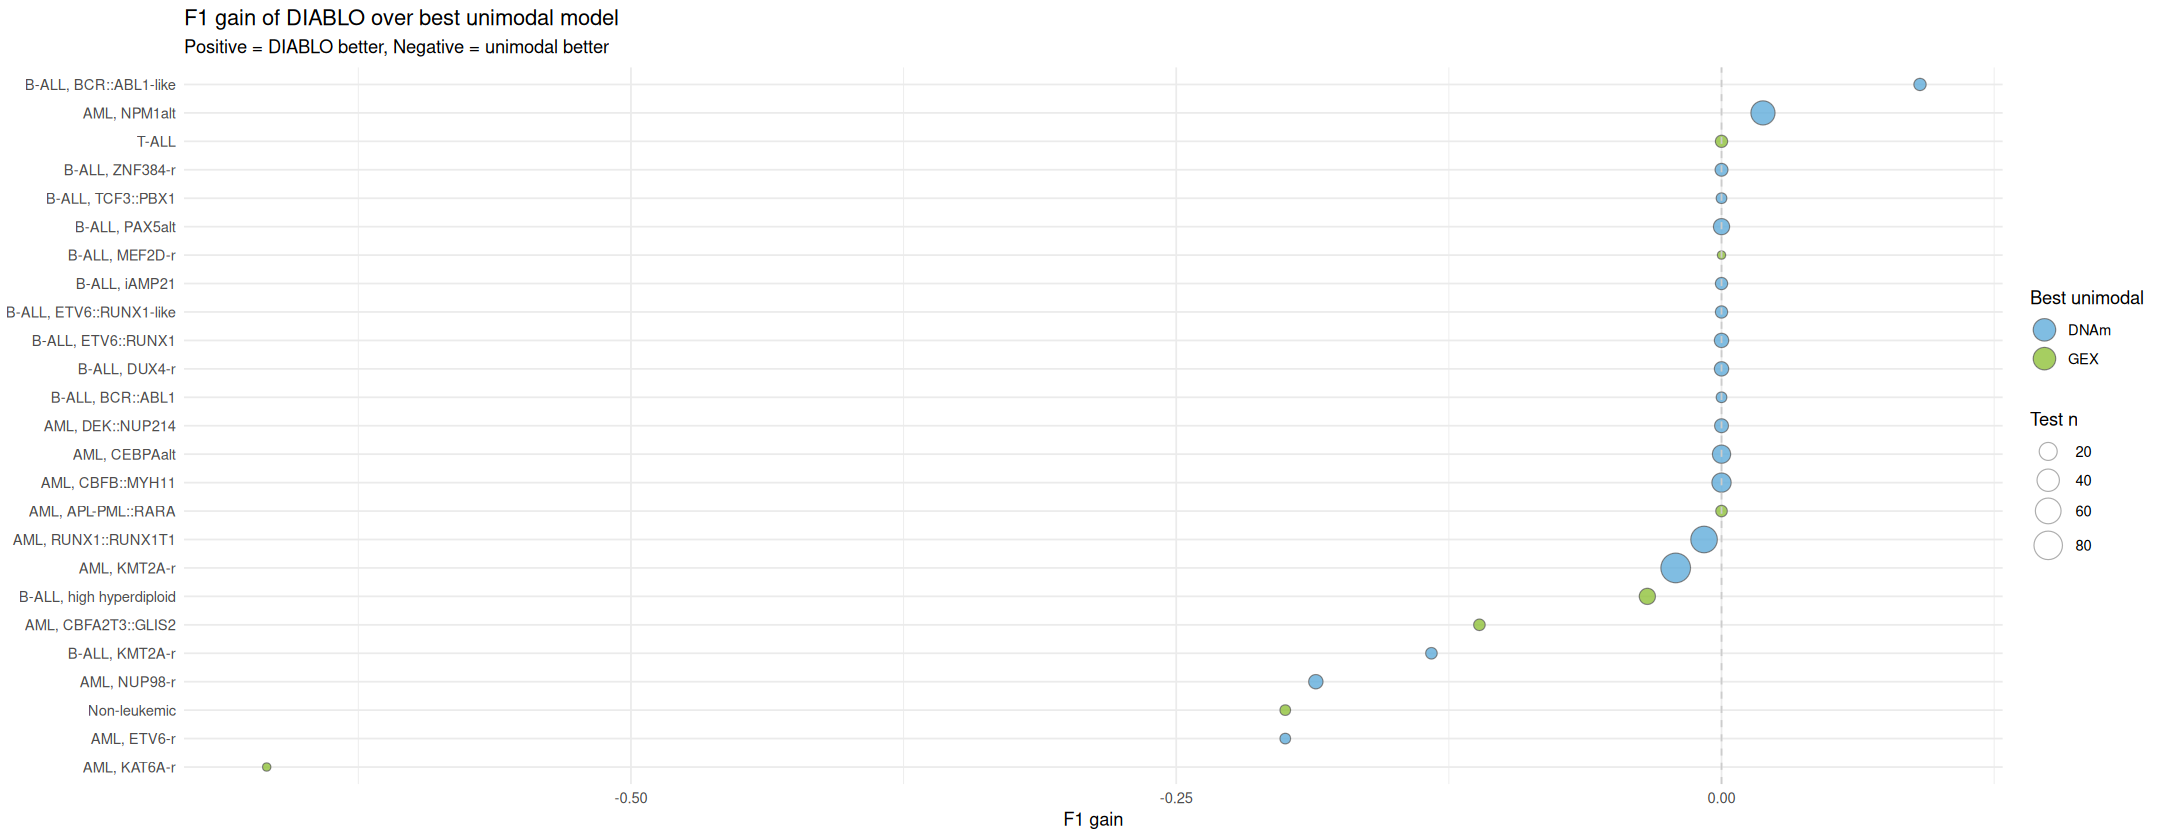

In [193]:
f1_wide <- f1_wide |>
  mutate(
    Best_unimodal    = pmax(GEX, DNAm),
    DIABLO_gain      = DIABLO - Best_unimodal,
    Best_unimodal_name = ifelse(GEX >= DNAm, "GEX", "DNAm")
  )

ggplot(f1_wide, aes(x = DIABLO_gain,
                    y = reorder(Class, DIABLO_gain),
                    fill = Best_unimodal_name,
                    size = n_test)) +
  geom_point(shape = 21, alpha = 0.8, colour = "grey40", stroke = 0.5) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "grey80") +
  scale_fill_manual(values = c(GEX = GREEN, DNAm = LIGHTBLUE), name = "Best unimodal") +
  scale_size_continuous(range = c(2, 8), name = "Test n") +
  guides(
    fill = guide_legend(override.aes = list(size = 6, stroke = 0.5, colour = "grey40")),
    size = guide_legend(override.aes = list(colour = "grey60", stroke = 0.5))
  ) +
  labs(title    = "F1 gain of DIABLO over best unimodal model",
       subtitle = "Positive = DIABLO better, Negative = unimodal better",
       x = "F1 gain", y = NULL) +
  theme_minimal()
  # Save as svg
ggsave(file.path(REPORT_OUTPUT_DIR, "diablo_gain_plot.svg"),
       width = 8, height = 6, units = "in")

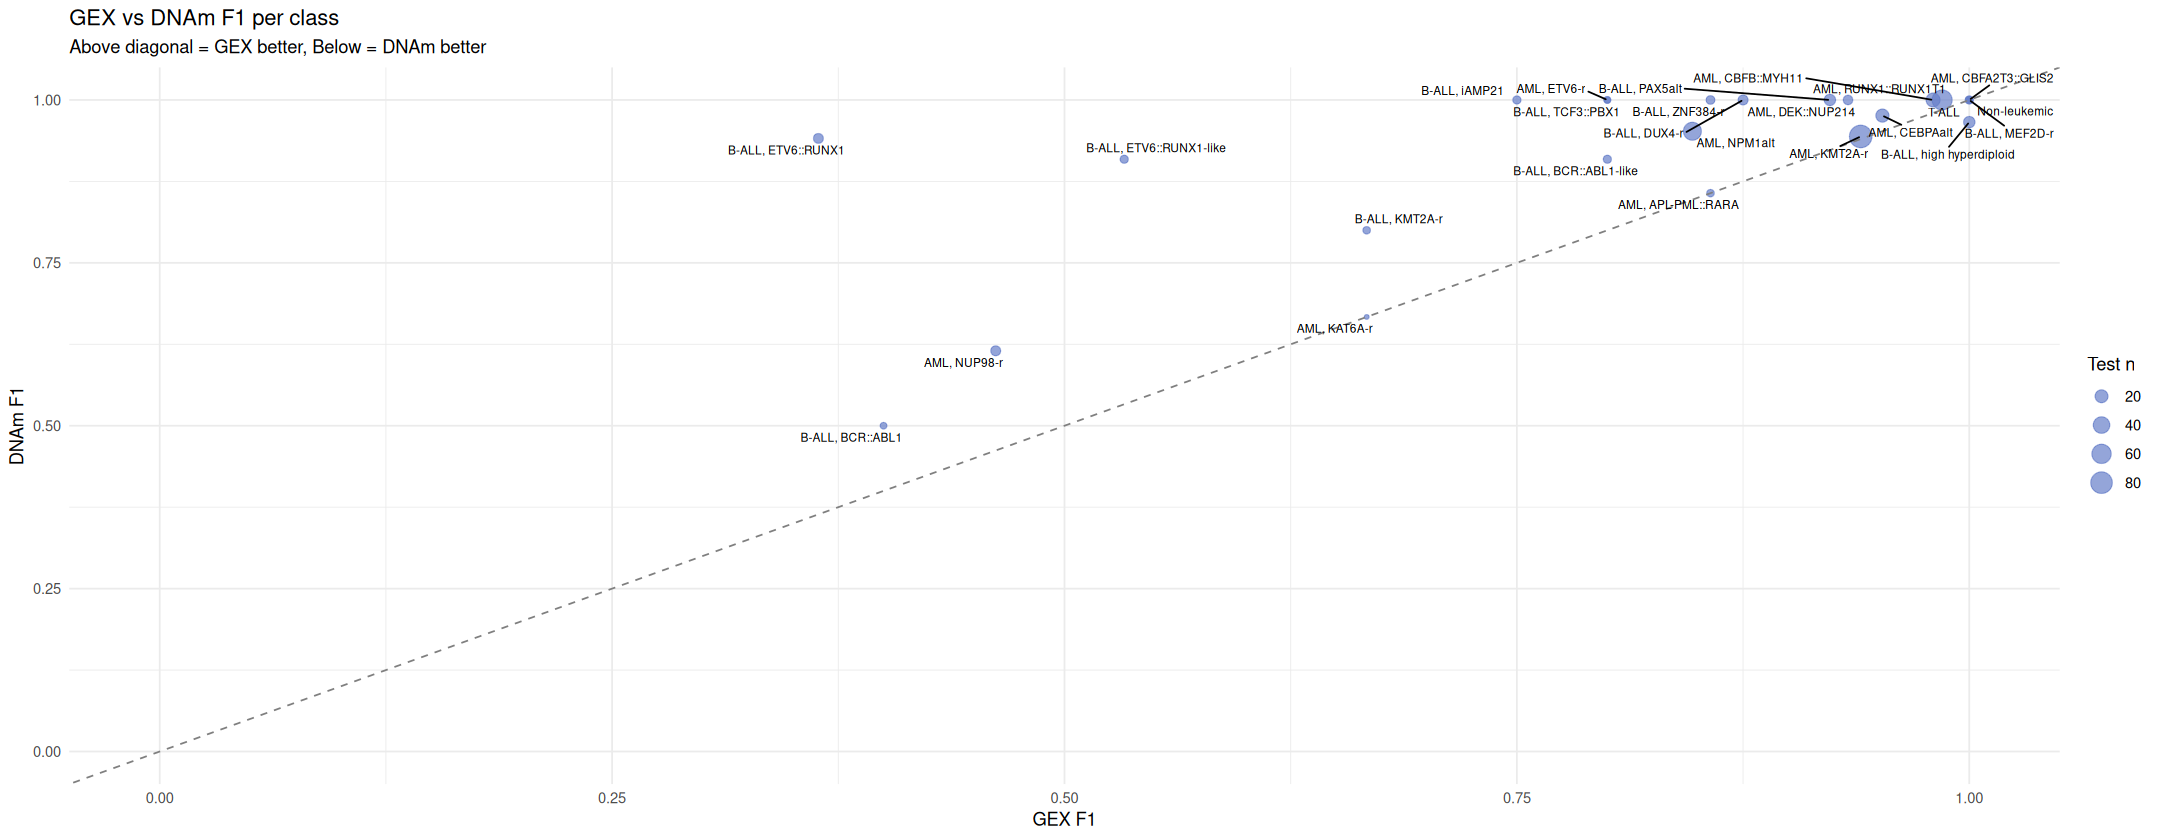

In [194]:
ggplot(f1_wide, aes(x = GEX, y = DNAm, size = n_test, label = Class)) +
  geom_point(alpha = 0.7, colour = BLUE) +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed", colour = "grey50") +
  geom_text_repel(size = 2.5, max.overlaps = 20) +
  xlim(0, 1) + ylim(0, 1) +
  labs(title = "GEX vs DNAm F1 per class",
       subtitle = "Above diagonal = GEX better, Below = DNAm better",
       x = "GEX F1", y = "DNAm F1", size = "Test n") +
  theme_minimal()

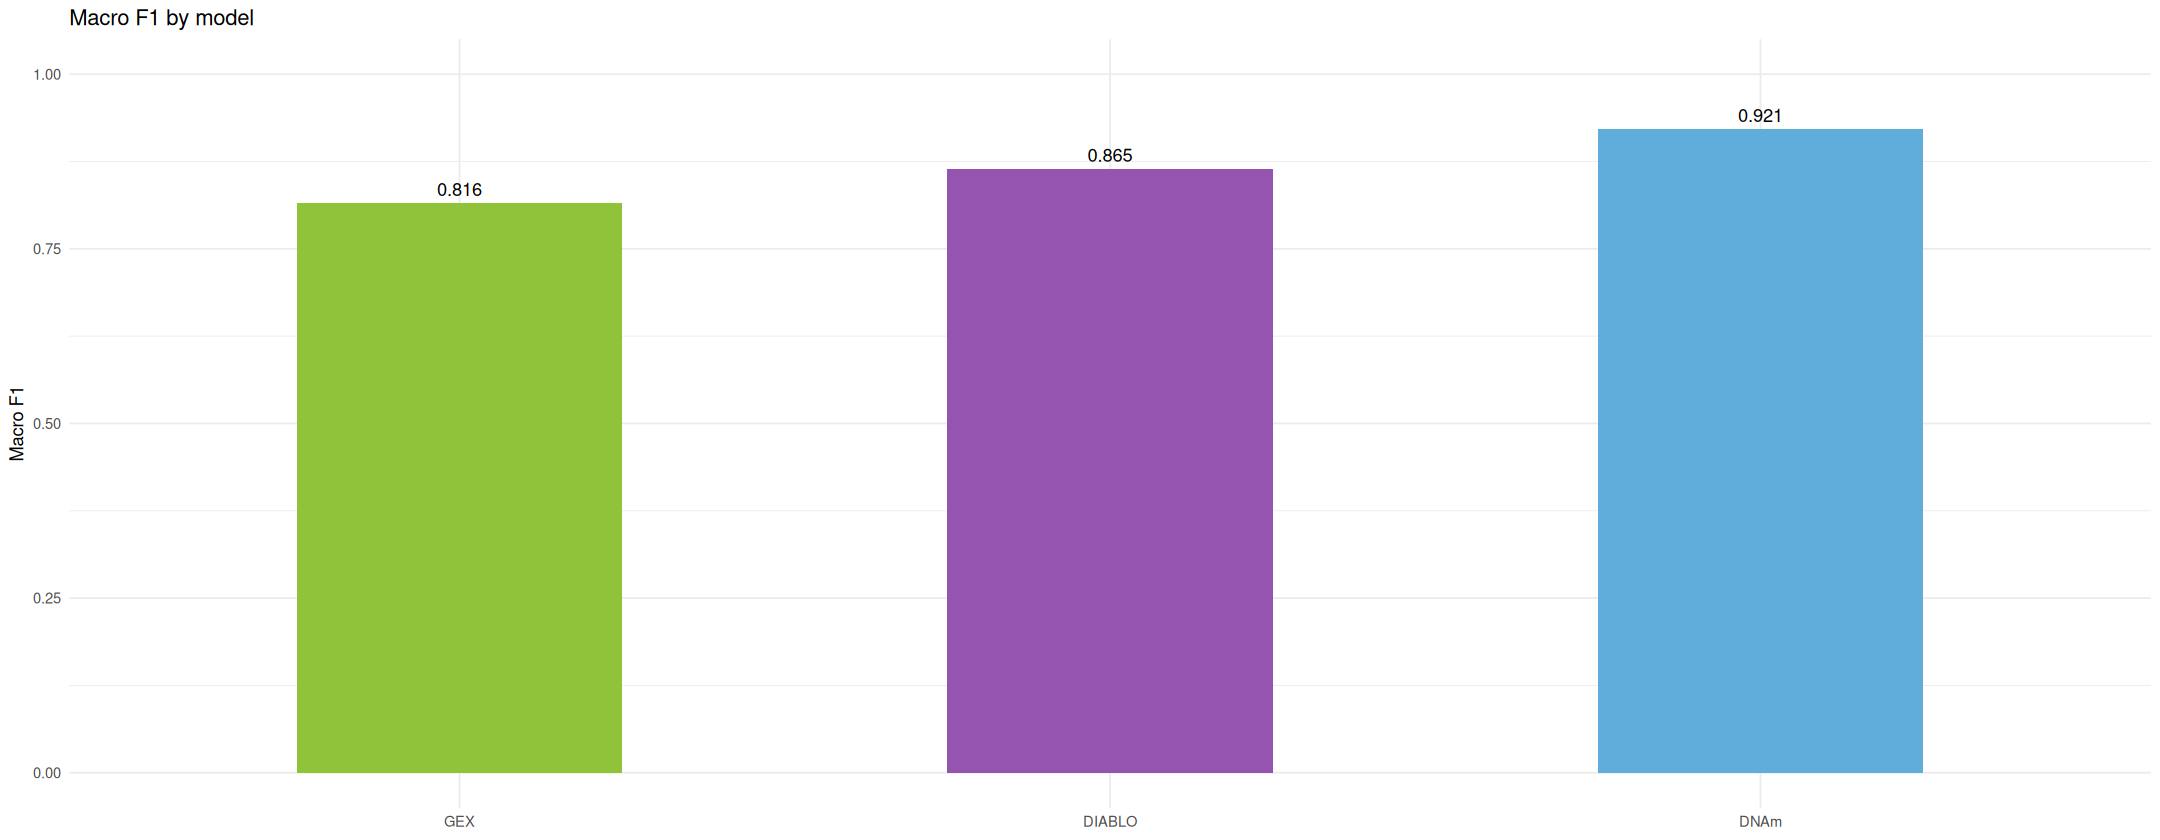

In [195]:
macro_f1 <- f1_all |>
  group_by(Model) |>
  summarise(MacroF1 = mean(F1), .groups = "drop")

ggplot(macro_f1, aes(x = reorder(Model, MacroF1), y = MacroF1, fill = Model)) +
  geom_bar(stat = "identity", width = 0.5) +
  geom_text(aes(label = round(MacroF1, 3)), vjust = -0.5) +
  scale_fill_manual(values = c(GEX = GREEN,
                                DNAm = LIGHTBLUE,
                                DIABLO = PURPLE)) +
  ylim(0, 1) +
  labs(title = "Macro F1 by model", x = NULL, y = "Macro F1") +
  theme_minimal() +
  theme(legend.position = "none")

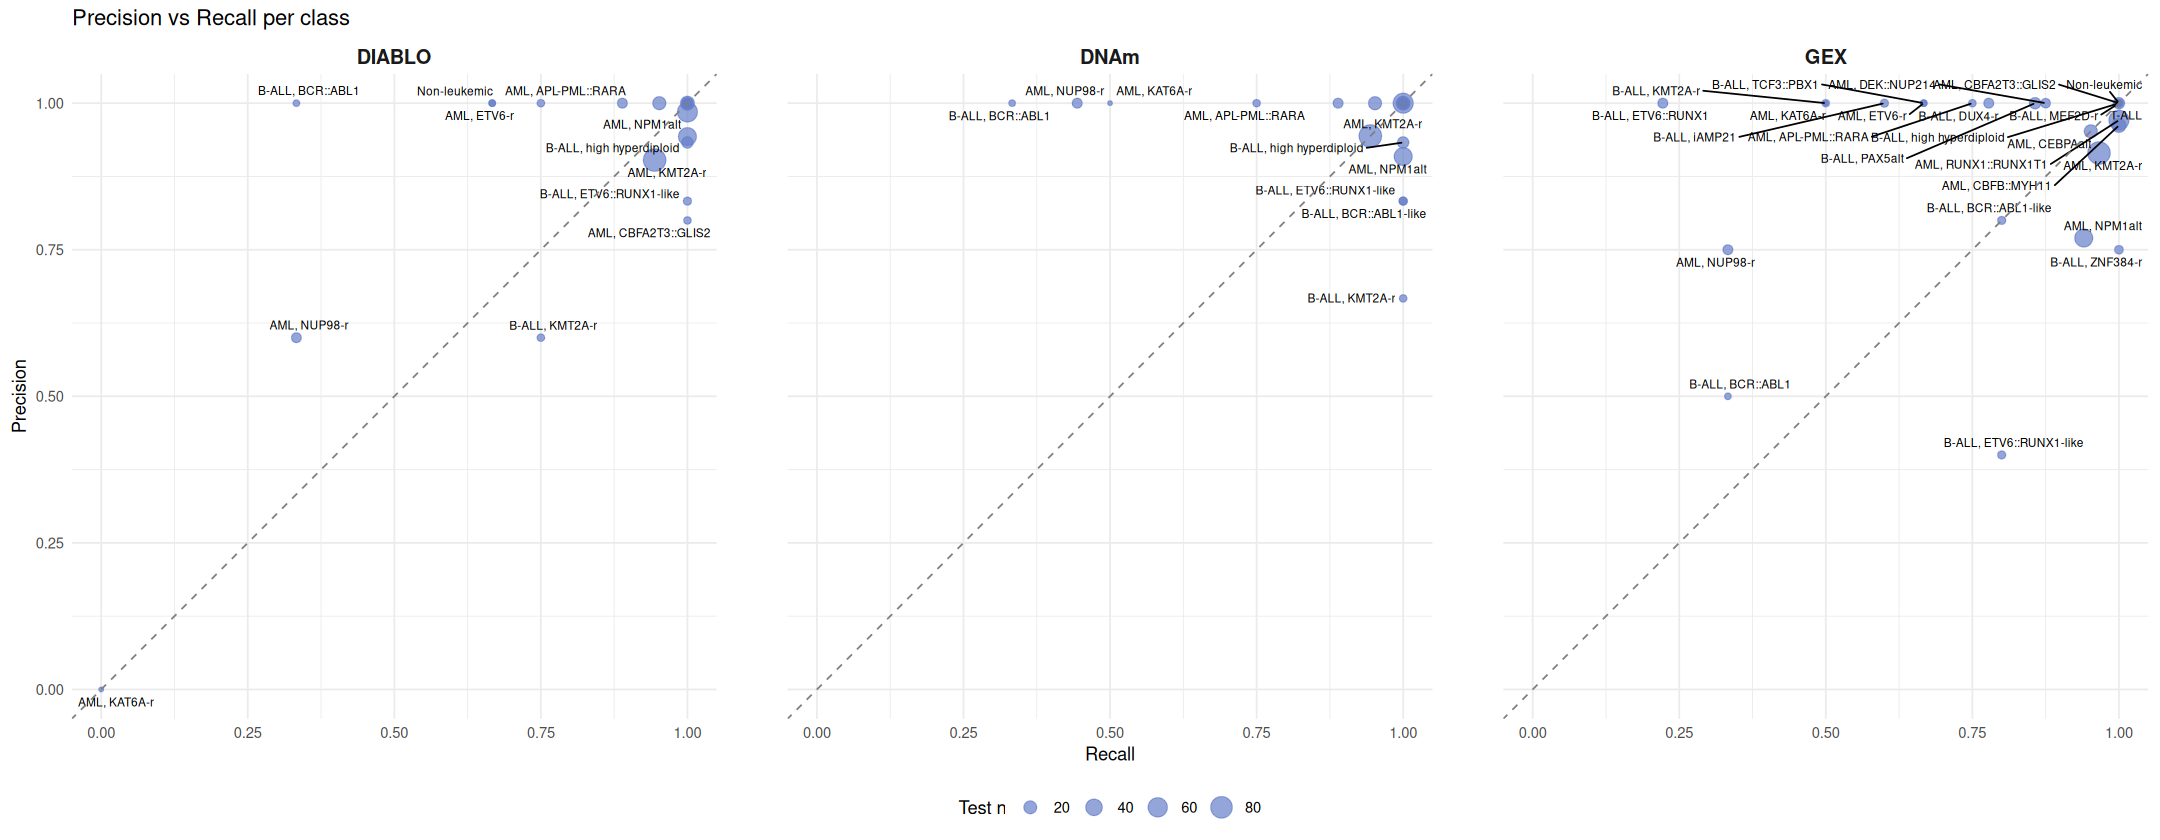

In [196]:
options(repr.plot.width = 18, repr.plot.height = 7)

class_n <- class_n_test %>% dplyr::rename(n = n_test)

plot_df <- left_join(f1_all, class_n, by = "Class")

ggplot(plot_df, aes(x = Recall, y = Precision, size = n, label = Class)) +
  geom_point(alpha = 0.7, colour = BLUE) +
  geom_text_repel(size = 2.5, max.overlaps = 15) +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed", colour = "grey50") +
  facet_wrap(~ Model, nrow = 1) +
  xlim(0, 1) + ylim(0, 1) +
  coord_fixed(ratio = 1) +
  labs(title = "Precision vs Recall per class", size = "Test n") +
  theme_minimal() +
  theme(
    panel.spacing   = unit(1.5, "cm"),
    strip.text      = element_text(size = 12, face = "bold"),
    legend.position = "bottom"
  )

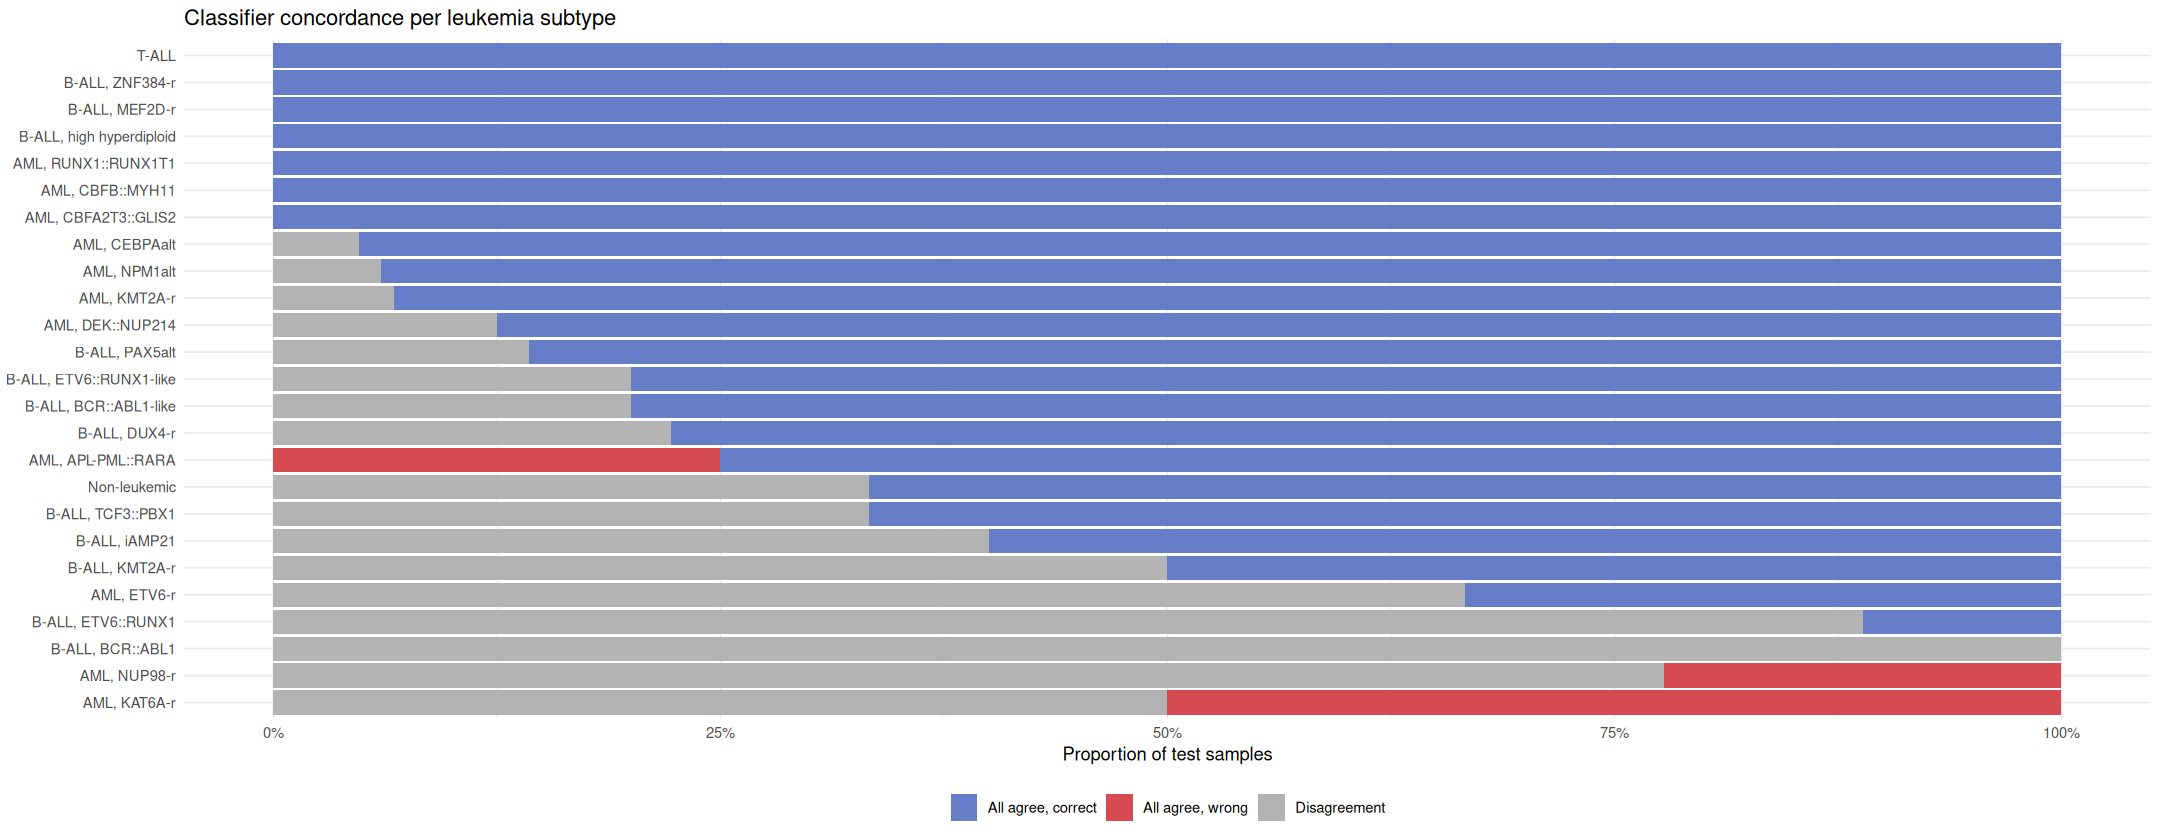

In [197]:
library(ggplot2)
library(dplyr)

# ============================================================
# Compute per-sample concordance
# ============================================================
results_df <- results_df |>
  mutate(
    # How many models agree with each other
    n_agree = (gex_pred == dnam_pred) +
              (gex_pred == diablo_pred) +
              (dnam_pred == diablo_pred),

    # All three agree
    all_agree = gex_pred == dnam_pred & dnam_pred == diablo_pred,

    # All three agree AND correct
    all_correct = all_agree & gex_pred == true_label,

    # Concordance label
    concordance = case_when(
      all_agree & gex_pred == true_label  ~ "All agree, correct",
      all_agree & gex_pred != true_label  ~ "All agree, wrong",
      !all_agree                           ~ "Disagreement"
    )
  )

# ============================================================
# 1. Stacked bar — concordance per true class
# ============================================================
conc_summary <- results_df |>
  group_by(true_label, concordance) |>
  summarise(n = n(), .groups = "drop") |>
  group_by(true_label) |>
  mutate(pct = n / sum(n))

ggplot(conc_summary,
       aes(x = pct,
           y = reorder(true_label, pct * (concordance == "All agree, correct")),
           fill = concordance)) +
  geom_bar(stat = "identity") +
  scale_fill_manual(values = c("All agree, correct" = BLUE,
                                "All agree, wrong"   = RED,
                                "Disagreement"       = "grey70")) +
  scale_x_continuous(labels = scales::percent) +
  labs(title = "Classifier concordance per leukemia subtype",
       x = "Proportion of test samples", y = NULL, fill = NULL) +
  theme_minimal() +
  theme(legend.position = "bottom")

# Save as svg
ggsave(file.path(REPORT_OUTPUT_DIR, "concordance_plot.svg"),
       width = 8, height = 6, units = "in")


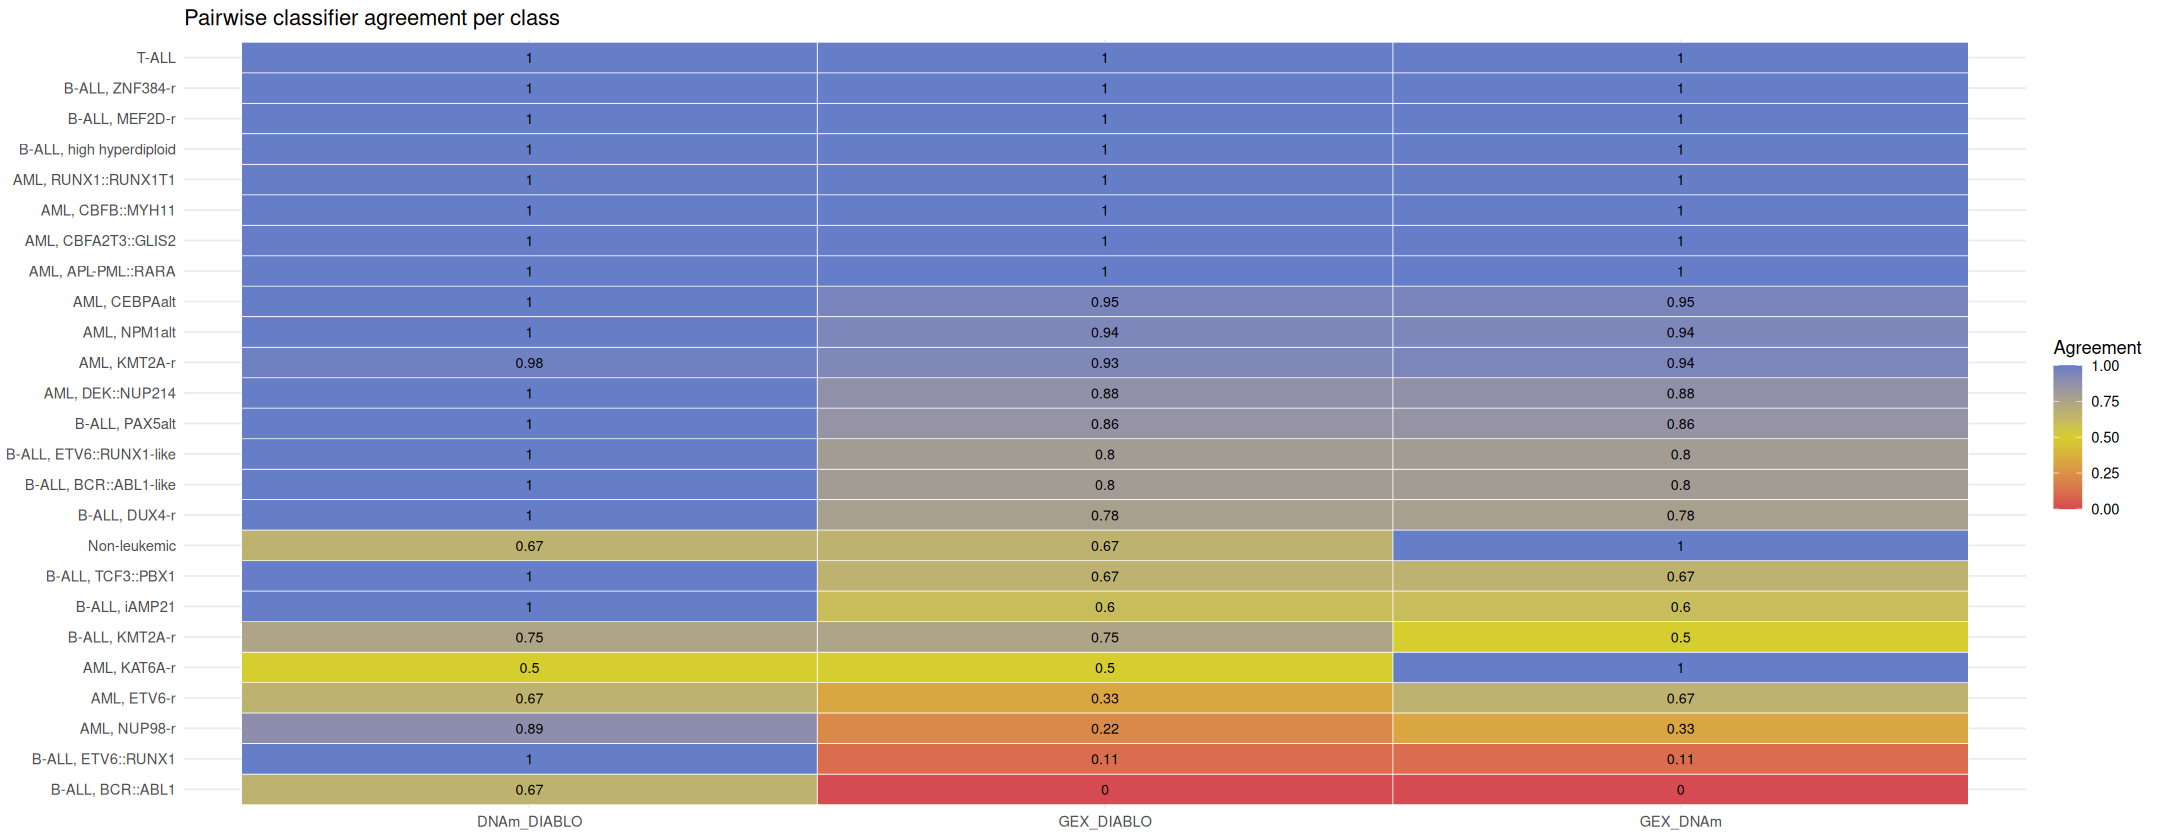

In [198]:

# ============================================================
# 2. Tile plot — pairwise agreement per class
# ============================================================
pairwise <- results_df |>
  group_by(true_label) |>
  summarise(
    GEX_DNAm    = mean(gex_pred == dnam_pred),
    GEX_DIABLO  = mean(gex_pred == diablo_pred),
    DNAm_DIABLO = mean(dnam_pred == diablo_pred),
    .groups = "drop"
  ) |>
  pivot_longer(cols = c("GEX_DNAm","GEX_DIABLO","DNAm_DIABLO"),
               names_to = "Pair", values_to = "Agreement")

ggplot(pairwise, aes(x = Pair,
                      y = reorder(true_label, Agreement),
                      fill = Agreement)) +
  geom_tile(colour = "white") +
  scale_fill_gradient2(low = RED, mid = YELLOW, high = BLUE,
                       midpoint = 0.5, limits = c(0, 1)) +
  geom_text(aes(label = round(Agreement, 2)), size = 3) +
  labs(title = "Pairwise classifier agreement per class",
       x = NULL, y = NULL, fill = "Agreement") +
  theme_minimal()

# Save as svg
ggsave(file.path(REPORT_OUTPUT_DIR, "pairwise_agreement_plot.svg"),
       width = 8, height = 6, units = "in")


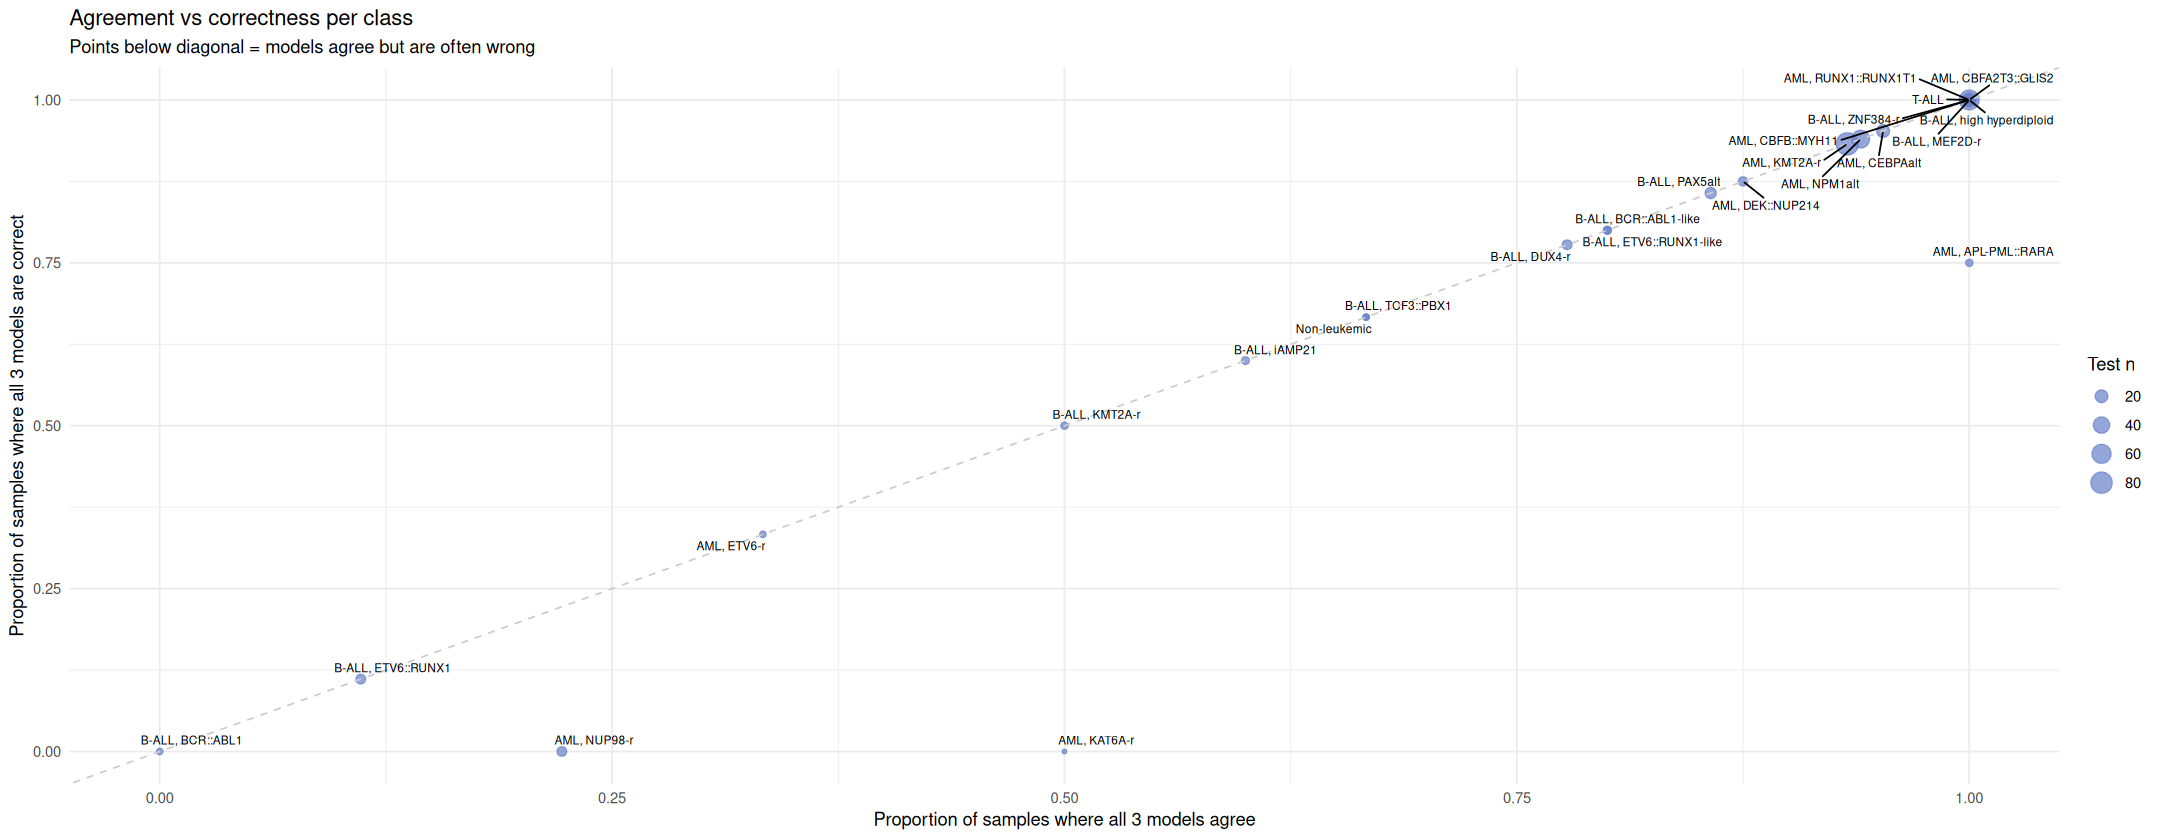

In [199]:

# ============================================================
# 3. Scatter — per class: % all-agree vs % correct
# ============================================================
class_conc <- results_df |>
  group_by(true_label) |>
  summarise(
    n          = n(),
    pct_agree  = mean(all_agree),
    pct_correct = mean(gex_pred == true_label &
                       dnam_pred == true_label &
                       diablo_pred == true_label),
    .groups = "drop"
  )

ggplot(class_conc, aes(x = pct_agree, y = pct_correct,
                        size = n, label = true_label)) +
  geom_point(alpha = 0.7, colour = BLUE) +
  geom_abline(slope = 1, intercept = 0,
              linetype = "dashed", colour = "grey80") +
  geom_text_repel(size = 2.5, max.overlaps = 20) +
  xlim(0, 1) + ylim(0, 1) +
  labs(title    = "Agreement vs correctness per class",
       subtitle = "Points below diagonal = models agree but are often wrong",
       x = "Proportion of samples where all 3 models agree",
       y = "Proportion of samples where all 3 models are correct",
       size = "Test n") +
  theme_minimal()

# Save as svg
ggsave(file.path(REPORT_OUTPUT_DIR, "agreement_correctness_plot.svg"),
       width = 8, height = 6, units = "in")

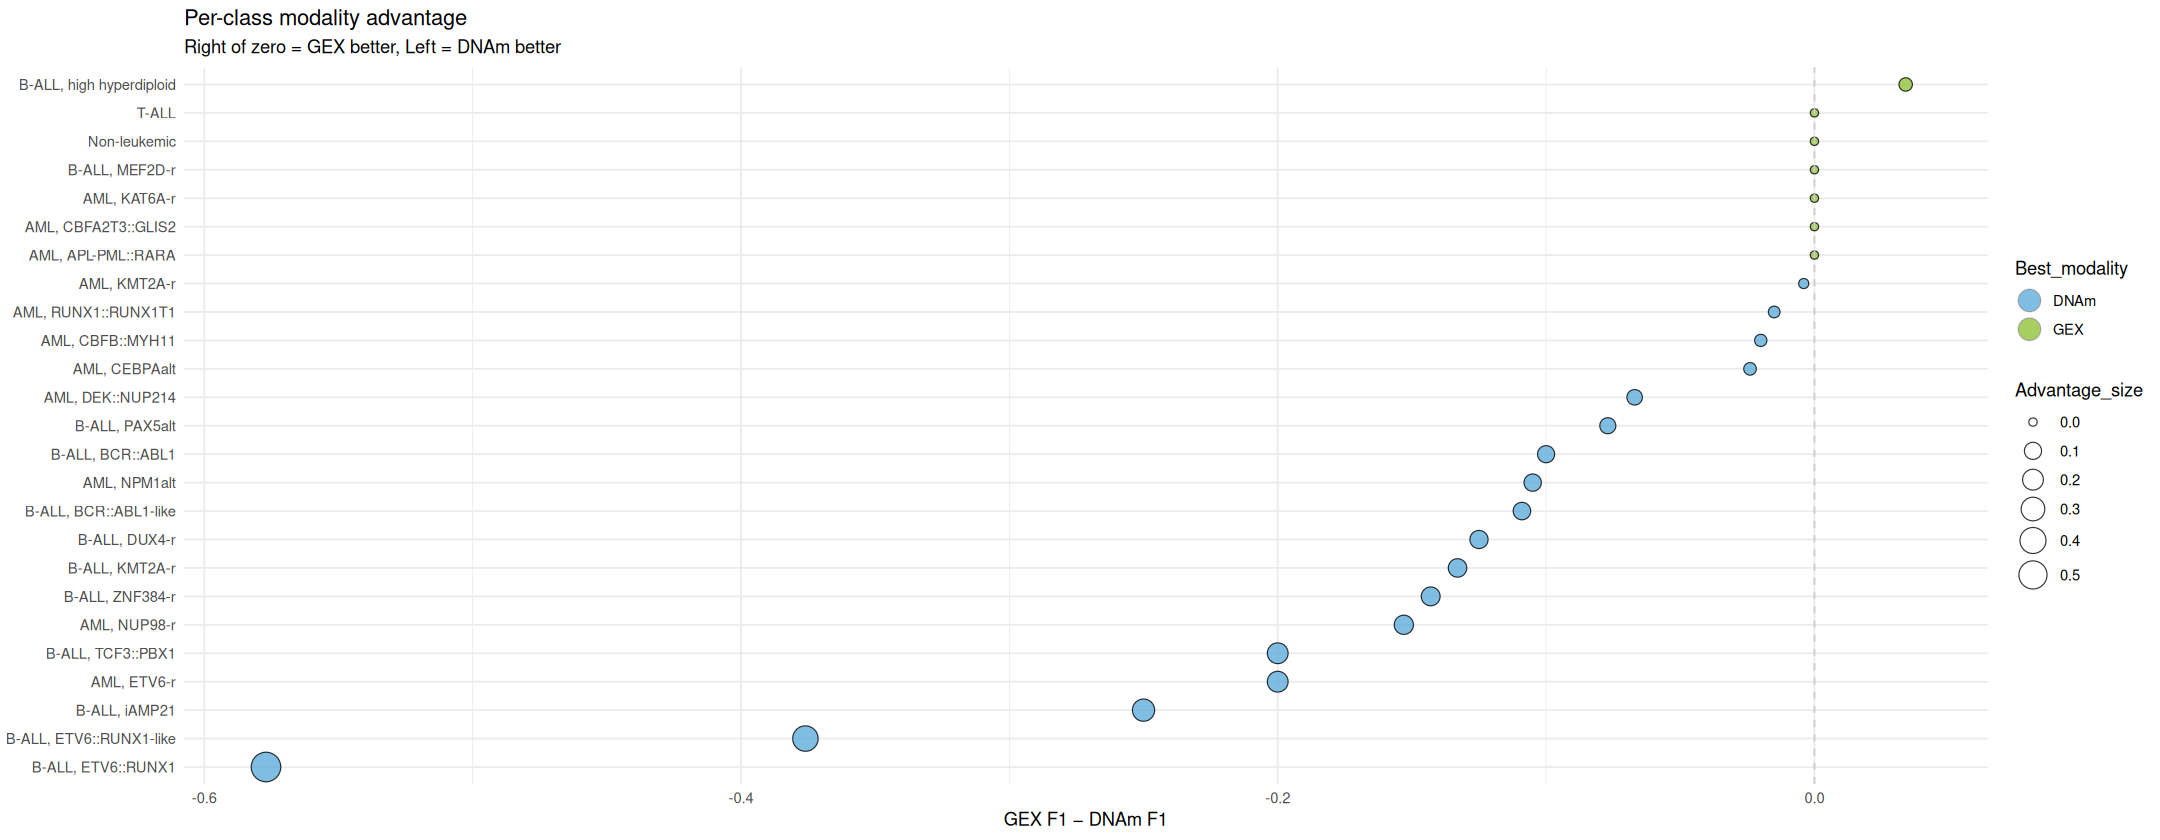

In [200]:
# Using per_class_f1() from earlier
complement_df <- data.frame(
  Class = classes,
  GEX   = f1_gex$F1,
  DNAm  = f1_dnam$F1
) |>
  mutate(
    GEX_advantage  = GEX - DNAm,
    Best_modality  = ifelse(GEX >= DNAm, "GEX", "DNAm"),
    Advantage_size = abs(GEX - DNAm)
  )

ggplot(complement_df,
       aes(x = GEX_advantage,
           y = reorder(Class, GEX_advantage),
           fill = Best_modality,
           size = Advantage_size)) +
  geom_point(shape = 21, alpha = 0.8) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "grey80") +
  scale_fill_manual(values = c(GEX = GREEN, DNAm = LIGHTBLUE)) +
  scale_size_continuous(range = c(2, 8)) +
  guides(fill = guide_legend(override.aes = list(colour = "grey60", size = 6))) +
  labs(title    = "Per-class modality advantage",
       subtitle = "Right of zero = GEX better, Left = DNAm better",
       x = "GEX F1 − DNAm F1",
       y = NULL) +
  theme_minimal()

  # Save as svg
ggsave(file.path(REPORT_OUTPUT_DIR, "per_class_modality_advantage_plot_by_advantage_size.svg"),
       width = 8, height = 6, units = "in")


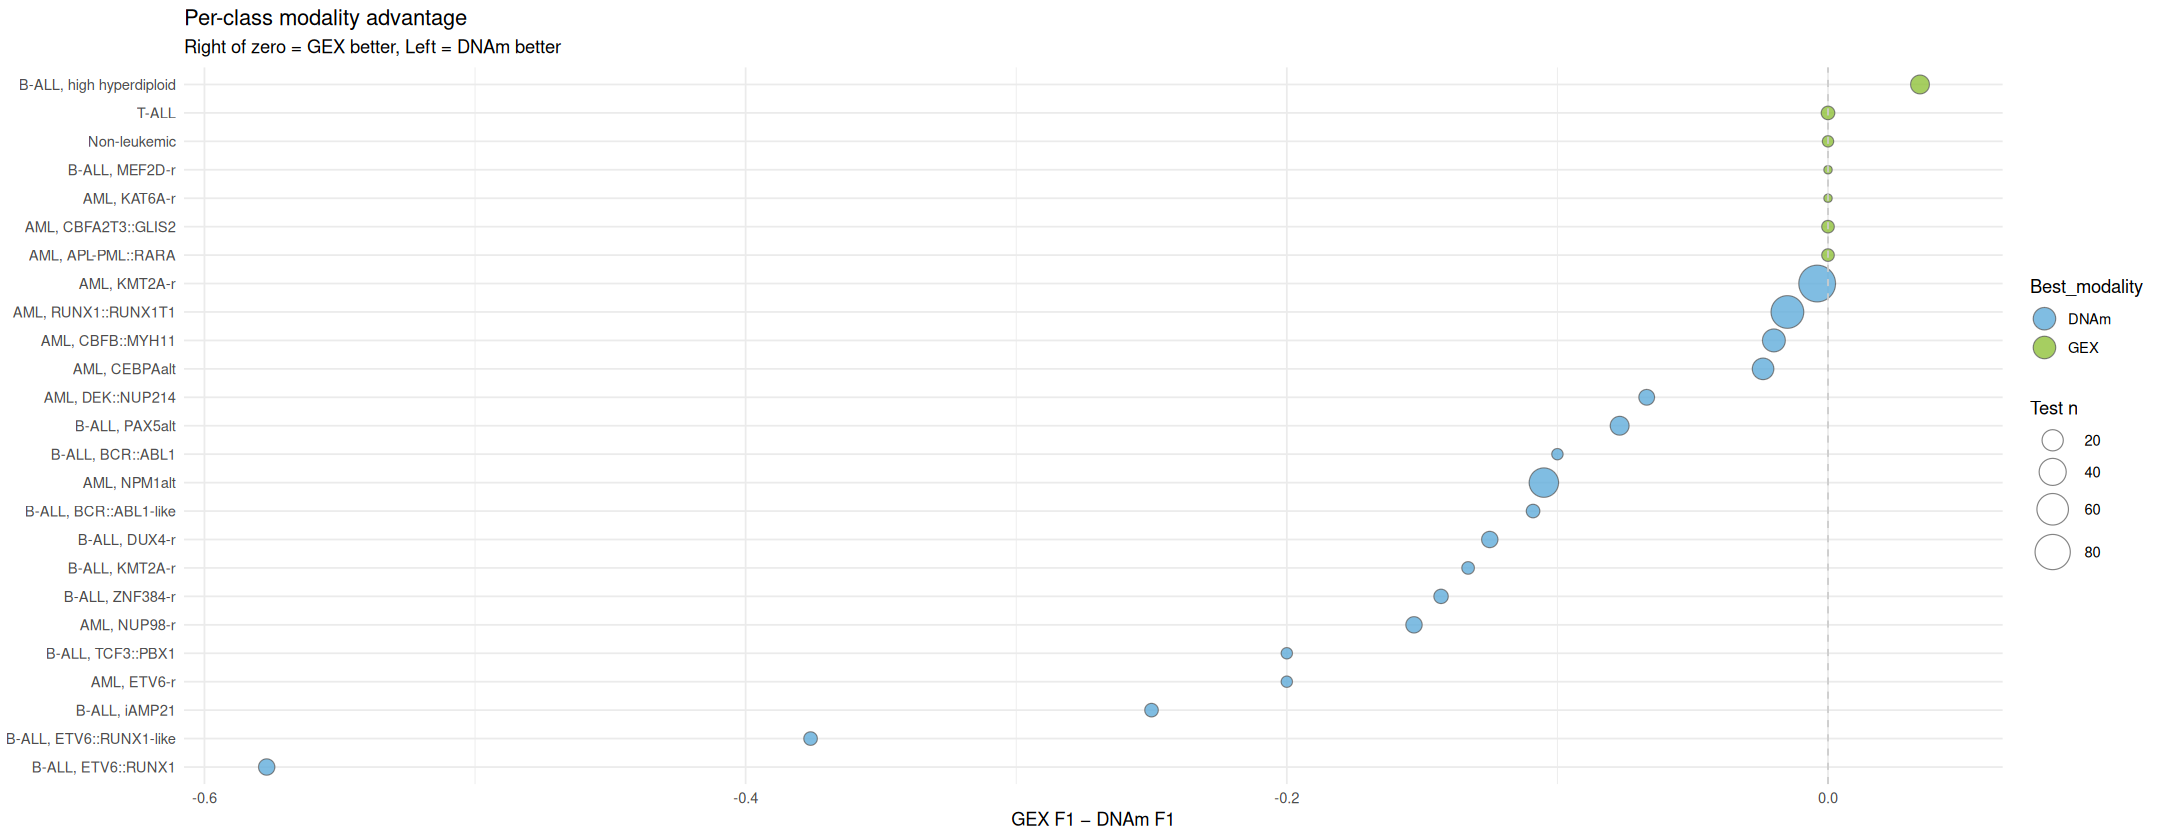

In [201]:
# Add class sizes
class_n_test <- f1_wide %>% select(Class, n_test)

complement_df <- data.frame(
  Class = classes,
  GEX   = f1_gex$F1,
  DNAm  = f1_dnam$F1
) |>
  mutate(
    GEX_advantage  = GEX - DNAm,
    Best_modality  = ifelse(GEX >= DNAm, "GEX", "DNAm"),
    Advantage_size = abs(GEX - DNAm)
  ) |>
  left_join(class_n_test, by = "Class")

ggplot(complement_df,
       aes(x = GEX_advantage,
           y = reorder(Class, GEX_advantage),
           fill = Best_modality,
           size = n_test)) +
  geom_point(shape = 21, alpha = 0.8, colour = "grey40") +
  guides(fill = guide_legend(override.aes = list(size = 6))) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "grey80") +
  scale_fill_manual(values = c(GEX = GREEN, DNAm = LIGHTBLUE)) +
  scale_size_continuous(range = c(2, 10), name = "Test n") +
  labs(title    = "Per-class modality advantage",
       subtitle = "Right of zero = GEX better, Left = DNAm better",
       x        = "GEX F1 − DNAm F1",
       y        = NULL) +
  theme_minimal()

  # Save as svg
ggsave(file.path(REPORT_OUTPUT_DIR, "per_class_modality_advantage_plot_by_sample_size.svg"),
       width = 8, height = 6, units = "in")

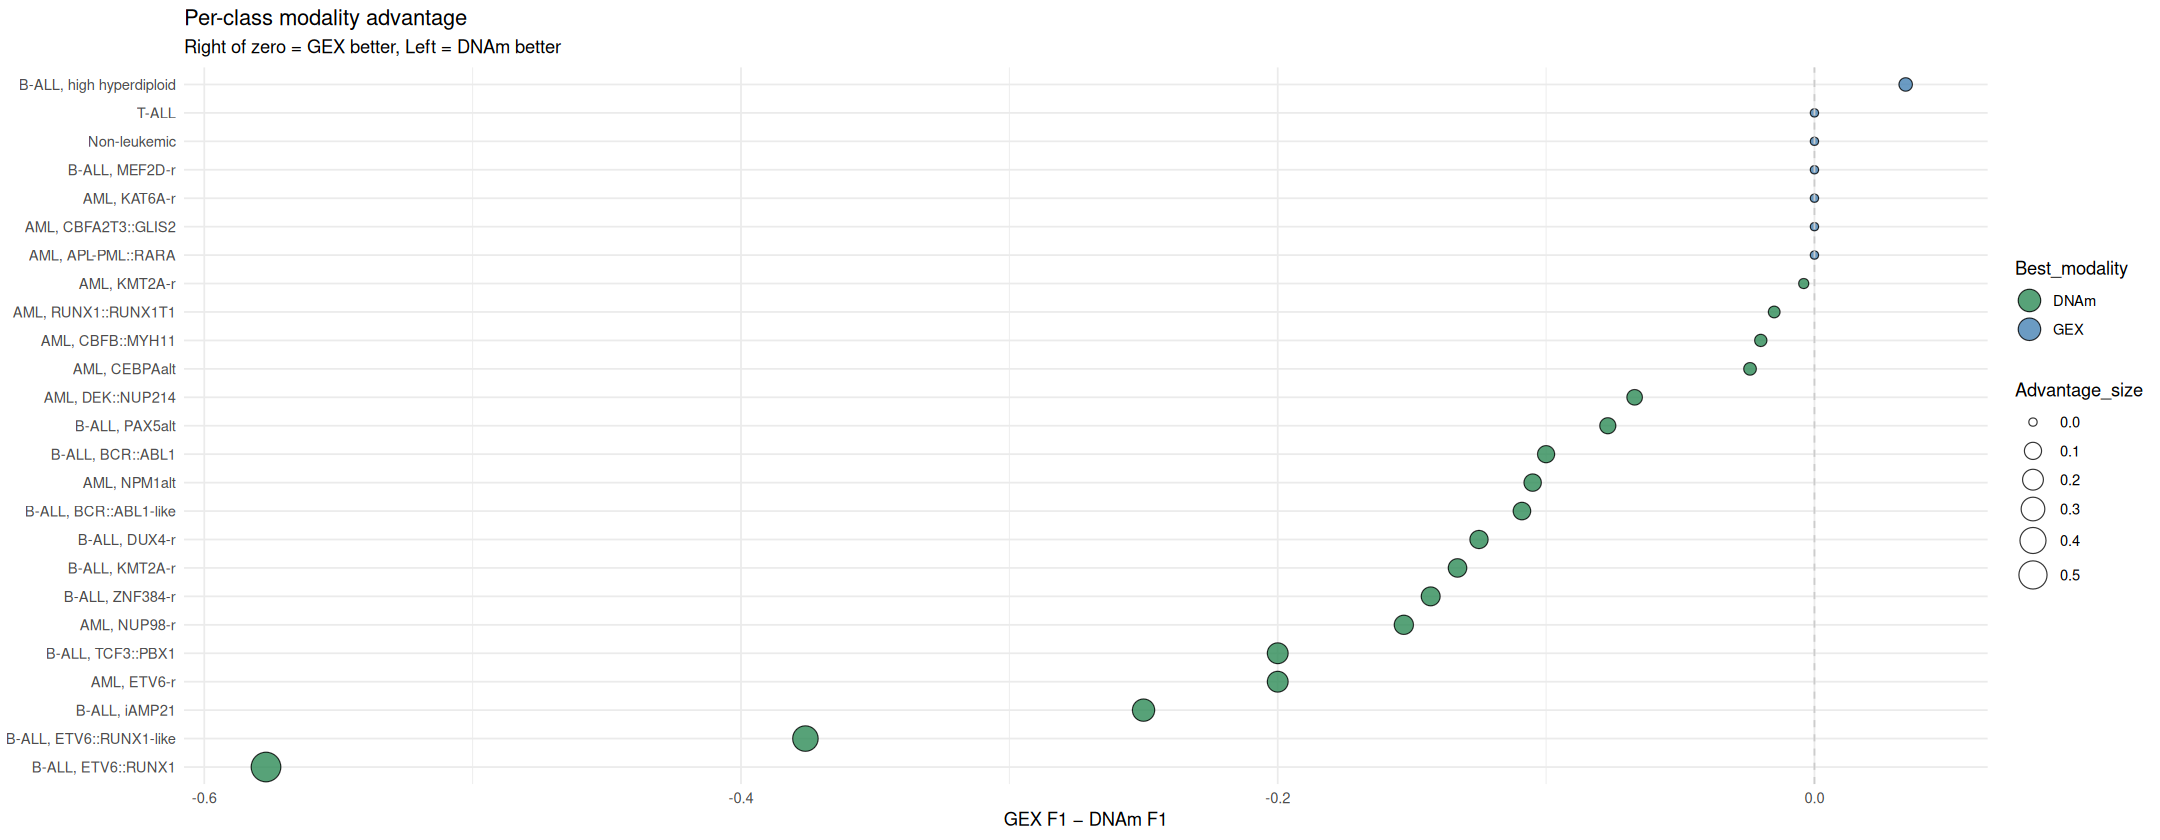

In [202]:
# Using per_class_f1() from earlier
complement_df <- data.frame(
  Class = classes,
  GEX   = f1_gex$F1,
  DNAm  = f1_dnam$F1
) |>
  mutate(
    GEX_advantage  = GEX - DNAm,
    Best_modality  = ifelse(GEX >= DNAm, "GEX", "DNAm"),
    Advantage_size = abs(GEX - DNAm)
  )

ggplot(complement_df,
       aes(x = GEX_advantage,
           y = reorder(Class, GEX_advantage),
           fill = Best_modality,
           size = Advantage_size)) +
  geom_point(shape = 21, alpha = 0.8) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "grey80") +
  guides(fill = guide_legend(override.aes = list(size = 6))) +
  scale_fill_manual(values = c(GEX = "steelblue", DNAm = "seagreen")) +
  scale_size_continuous(range = c(2, 8)) +
  labs(title    = "Per-class modality advantage",
       subtitle = "Right of zero = GEX better, Left = DNAm better",
       x = "GEX F1 − DNAm F1",
       y = NULL) +
  theme_minimal()

# Save as svg
ggsave(file.path(REPORT_OUTPUT_DIR, "per_class_modality_advantage_plot.svg"),
       width = 8, height = 6, units = "in")

In [203]:

# Extract F1 vectors per model
f1_gex_vec    <- f1_wide$GEX
f1_dnam_vec   <- f1_wide$DNAm
f1_diablo_vec <- f1_wide$DIABLO

# ============================================================
# Pairwise Wilcoxon signed-rank tests
# ============================================================
wt_gex_dnam   <- wilcox.test(f1_gex_vec, f1_dnam_vec,
                              paired = TRUE, exact = FALSE)
wt_gex_diablo <- wilcox.test(f1_gex_vec, f1_diablo_vec,
                              paired = TRUE, exact = FALSE)
wt_dnam_diablo <- wilcox.test(f1_dnam_vec, f1_diablo_vec,
                               paired = TRUE, exact = FALSE)

# ============================================================
# Summary table
# ============================================================
wilcox_results <- data.frame(
  Comparison     = c("GEX vs DNAm", "GEX vs DIABLO", "DNAm vs DIABLO"),
  Mean_F1_A      = round(c(mean(f1_gex_vec),
                            mean(f1_gex_vec),
                            mean(f1_dnam_vec)), 3),
  Mean_F1_B      = round(c(mean(f1_dnam_vec),
                            mean(f1_diablo_vec),
                            mean(f1_diablo_vec)), 3),
  W_statistic    = c(wt_gex_dnam$statistic,
                     wt_gex_diablo$statistic,
                     wt_dnam_diablo$statistic),
  p_value        = round(c(wt_gex_dnam$p.value,
                            wt_gex_diablo$p.value,
                            wt_dnam_diablo$p.value), 4),
  p_adj_BH       = round(p.adjust(c(wt_gex_dnam$p.value,
                                     wt_gex_diablo$p.value,
                                     wt_dnam_diablo$p.value),
                                   method = "BH"), 4)
)

print(wilcox_results)

      Comparison Mean_F1_A Mean_F1_B W_statistic p_value p_adj_BH
1    GEX vs DNAm     0.816     0.921           5  0.0003   0.0009
2  GEX vs DIABLO     0.816     0.865          58  0.0825   0.0825
3 DNAm vs DIABLO     0.921     0.865          49  0.0322   0.0483
